<a href="https://colab.research.google.com/github/AnjanaVP231/ML/blob/main/Lab1_linearRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving DatasetLR (1).csv to DatasetLR (1) (2).csv
First 10 records:


,Study_Hours,Sleep_Hours,Attendance,Previous_Score,Assignments_Completed,Exam_Score
0,1.5,5.7,93,88,92,60.9
1,6.5,6.6,72,69,79,82.1
2,4.1,7.9,92,50,74,71.4
3,6.1,6.8,98,90,75,84.9
4,7.8,7.3,88,52,99,89.0
5,4.8,7.7,79,66,64,72.0
6,4.5,8.0,90,72,96,72.4
7,1.5,7.8,91,86,94,61.4
8,2.9,5.5,90,83,69,64.6
9,4.5,6.8,74,74,74,71.9



Number of rows and columns:
(100, 6)

Column names:
['Study_Hours', 'Sleep_Hours', 'Attendance', 'Previous_Score', 'Assignments_Completed', 'Exam_Score']

Missing values:
Study_Hours              0
Sleep_Hours              0
Attendance               0
Previous_Score           0
Assignments_Completed    0
Exam_Score               0
dtype: int64

Duplicate records:
0

Dependent Variable:
Exam_Score

Independent Variables:
['Study_Hours', 'Sleep_Hours', 'Attendance', 'Previous_Score', 'Assignments_Completed']

Correlation Matrix:


,Study_Hours,Sleep_Hours,Attendance,Previous_Score,Assignments_Completed,Exam_Score
Study_Hours,1.000000,0.155749,0.080967,-0.147930,-0.037457,0.958313
Sleep_Hours,0.155749,1.000000,-0.142734,-0.080044,0.143731,0.264658
Attendance,0.080967,-0.142734,1.000000,-0.110322,-0.025918,0.115301
Previous_Score,-0.147930,-0.080044,-0.110322,1.000000,0.003584,0.025894
Assignments_Completed,-0.037457,0.143731,-0.025918,0.003584,1.000000,0.074850
Exam_Score,0.958313,0.264658,0.115301,0.025894,0.074850,1.000000



Feature having strongest correlation with Exam_Score:
Study_Hours

Correlation value:
0.9583129078269176


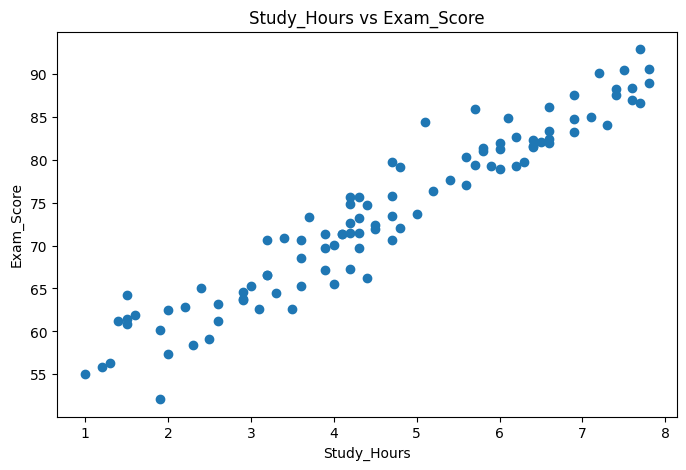


Multiple Linear Regression model trained successfully.

Intercept:
16.174179199719937

Coefficients:
Study_Hours: 5.070140870721533
Sleep_Hours: 1.3790053433452873
Attendance: 0.08238619792375568
Previous_Score: 0.15161054658767226
Assignments_Completed: 0.08536743324134649

Final Multiple Linear Regression Equation:
Exam_Score = 16.1742+(5.0701 × Study_Hours)+(1.3790 × Sleep_Hours)+(0.0824 × Attendance)+(0.1516 × Previous_Score)+(0.0854 × Assignments_Completed)

Model Evaluation:
MAE          : 0.8311
MSE          : 1.0113
RMSE         : 1.0057
R²           : 0.9884
Adjusted R²  : 0.9842

Comparison of Models:


,Model,MAE,MSE,RMSE,R²,Adjusted R²
0,Model 1,1.956783,5.231123,2.287165,0.939883,0.936544
1,Model 2,2.010808,5.627060,2.372142,0.935333,0.927725
2,Model 3,0.831091,1.011333,1.005650,0.988378,0.984227


Model with highest R²:
Model 3

Final Weights:
[9.4111671  1.25233809 0.7615085  1.75734702 0.98795329]

Final Bias:
73.67267715734685

Gradient Descent Evaluation:
MAE          : 0.8281
MSE          : 1.0085
RMSE         : 1.0042
R²           : 0.9884
Adjusted R²  : 0.9843


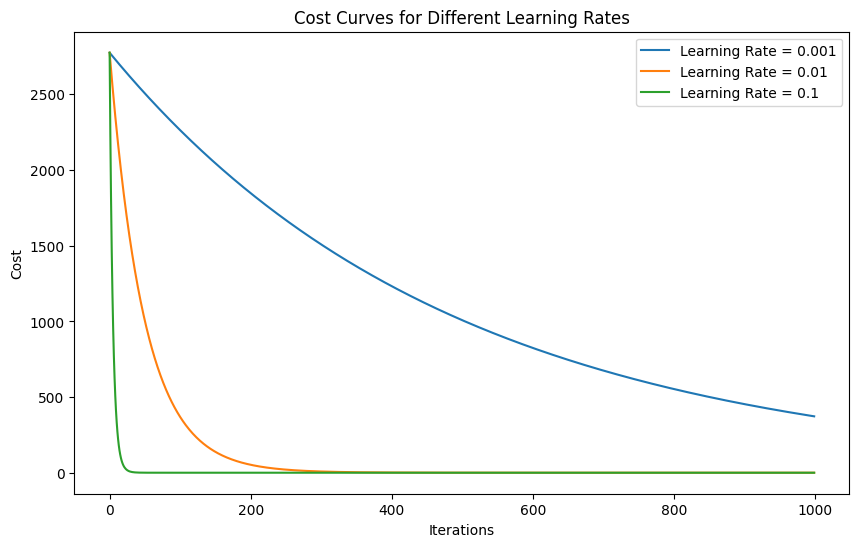


Learning Rate Comparison:


,Learning Rate,MAE,MSE,RMSE,R²,Adjusted R²
0,0.001,28.848200,850.936673,29.170819,-8.779052,-12.271570
1,0.010,0.828059,1.008495,1.004239,0.988410,0.984271
2,0.100,0.831091,1.011333,1.005650,0.988378,0.984227



Scikit-learn vs Gradient Descent:


,Metric,Scikit-learn Linear Regression,Gradient Descent
0,MAE,0.831091,0.828059
1,MSE,1.011333,1.008495
2,RMSE,1.005650,1.004239
3,R²,0.988378,0.988410
4,Adjusted R²,0.984227,0.984271



New Student:


,Study_Hours,Sleep_Hours,Attendance,Previous_Score,Assignments_Completed
0,5,7,85,75,85


Predicted Exam Score:
76.81


In [ ]:
# ============================================================
# LINEAR REGRESSION
# ============================================================

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# TASK 1: LOAD AND INSPECT THE DATASET
# ============================================================

# Upload dataset
uploaded = files.upload()

# Read the uploaded Excel file
file_name = list(uploaded.keys())[0]
df = pd.read_csv(file_name)

print("First 10 records:")
display(df.head(10))

print("\nNumber of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

# Identify dependent and independent variables
dependent_variable = "Exam_Score"

independent_variables = [
    "Study_Hours",
    "Sleep_Hours",
    "Attendance",
    "Previous_Score",
    "Assignments_Completed"
]

print("\nDependent Variable:")
print(dependent_variable)

print("\nIndependent Variables:")
print(independent_variables)


# ============================================================
# TASK 2: CORRELATION ANALYSIS
# ============================================================

# Calculate correlation matrix
correlation_matrix = df.corr(numeric_only=True)

print("\nCorrelation Matrix:")
display(correlation_matrix)

# Find feature having strongest correlation with Exam_Score
correlations = correlation_matrix["Exam_Score"].drop("Exam_Score")

strongest_feature = correlations.abs().idxmax()
strongest_correlation = correlations[strongest_feature]

print("\nFeature having strongest correlation with Exam_Score:")
print(strongest_feature)

print("\nCorrelation value:")
print(strongest_correlation)

# Scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(df[strongest_feature], df["Exam_Score"])
plt.xlabel(strongest_feature)
plt.ylabel("Exam_Score")
plt.title(f"{strongest_feature} vs Exam_Score")
plt.show()


# ============================================================
# TASK 3: MULTIPLE LINEAR REGRESSION
# ============================================================

X = df[independent_variables]
y = df["Exam_Score"]

# Split into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Train Multiple Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

print("\nMultiple Linear Regression model trained successfully.")


# ============================================================
# TASK 4: REGRESSION EQUATION
# ============================================================

intercept = model.intercept_
coefficients = model.coef_

print("\nIntercept:")
print(intercept)

print("\nCoefficients:")

for feature, coefficient in zip(independent_variables, coefficients):
    print(f"{feature}: {coefficient}")

# Display final regression equation
print("\nFinal Multiple Linear Regression Equation:")

equation = f"Exam_Score = {intercept:.4f}"

for feature, coefficient in zip(independent_variables, coefficients):
    equation += f"+({coefficient:.4f} × {feature})"

print(equation)


# ============================================================
# TASK 5: MODEL EVALUATION
# ============================================================

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

n = len(y_test)
p = X_test.shape[1]

adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("\nModel Evaluation:")
print(f"MAE          : {mae:.4f}")
print(f"MSE          : {mse:.4f}")
print(f"RMSE         : {rmse:.4f}")
print(f"R²           : {r2:.4f}")
print(f"Adjusted R²  : {adjusted_r2:.4f}")


# ============================================================
# TASK 6: EFFECT OF ADDING PREDICTORS
# ============================================================

model_features = {
    "Model 1": ["Study_Hours"],

    "Model 2": [
        "Study_Hours",
        "Sleep_Hours"
    ],

    "Model 3": [
        "Study_Hours",
        "Sleep_Hours",
        "Attendance",
        "Previous_Score",
        "Assignments_Completed"
    ]
}

results = []

for model_name, features in model_features.items():

    X_model = df[features]
    y_model = df["Exam_Score"]

    X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
        X_model,
        y_model,
        test_size=0.20,
        random_state=42
    )

    lr_model = LinearRegression()
    lr_model.fit(X_train_m, y_train_m)

    y_pred_m = lr_model.predict(X_test_m)

    mae_m = mean_absolute_error(y_test_m, y_pred_m)
    mse_m = mean_squared_error(y_test_m, y_pred_m)
    rmse_m = np.sqrt(mse_m)
    r2_m = r2_score(y_test_m, y_pred_m)

    n_m = len(y_test_m)
    p_m = X_test_m.shape[1]

    adjusted_r2_m = 1 - (
        (1 - r2_m) * (n_m - 1) / (n_m - p_m - 1)
    )

    results.append([
        model_name,
        mae_m,
        mse_m,
        rmse_m,
        r2_m,
        adjusted_r2_m
    ])

comparison_table = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R²",
        "Adjusted R²"
    ]
)

print("\nComparison of Models:")
display(comparison_table)

# Determine model based on highest R²
best_model = comparison_table.loc[
    comparison_table["R²"].idxmax(),
    "Model"
]

print("Model with highest R²:")
print(best_model)


# ============================================================
# TASK 7: MULTIPLE LINEAR REGRESSION USING GRADIENT DESCENT
# ============================================================

# Standardize input features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
y_values = y.values

# Train-test split
X_train_gd, X_test_gd, y_train_gd, y_test_gd = train_test_split(
    X_scaled,
    y_values,
    test_size=0.20,
    random_state=42
)

# Gradient Descent function
def gradient_descent(X, y, learning_rate=0.01, epochs=1000):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0

    cost_history = []

    for i in range(epochs):

        y_pred = np.dot(X, weights) + bias

        error = y_pred - y

        cost = np.mean(error ** 2) / 2
        cost_history.append(cost)

        dw = (1 / n_samples) * np.dot(X.T, error)
        db = (1 / n_samples) * np.sum(error)

        weights = weights - learning_rate * dw
        bias = bias - learning_rate * db

    return weights, bias, cost_history


# Train Gradient Descent model
weights, bias, cost_history = gradient_descent(
    X_train_gd,
    y_train_gd,
    learning_rate=0.01,
    epochs=1000
)

print("\nFinal Weights:")
print(weights)

print("\nFinal Bias:")
print(bias)

# Prediction
y_pred_gd = np.dot(X_test_gd, weights) + bias

# Evaluation
mae_gd = mean_absolute_error(y_test_gd, y_pred_gd)
mse_gd = mean_squared_error(y_test_gd, y_pred_gd)
rmse_gd = np.sqrt(mse_gd)
r2_gd = r2_score(y_test_gd, y_pred_gd)

n_gd = len(y_test_gd)
p_gd = X_test_gd.shape[1]

adjusted_r2_gd = 1 - (
    (1 - r2_gd) * (n_gd - 1) / (n_gd - p_gd - 1)
)

print("\nGradient Descent Evaluation:")
print(f"MAE          : {mae_gd:.4f}")
print(f"MSE          : {mse_gd:.4f}")
print(f"RMSE         : {rmse_gd:.4f}")
print(f"R²           : {r2_gd:.4f}")
print(f"Adjusted R²  : {adjusted_r2_gd:.4f}")


# ============================================================
# TASK 8: LEARNING RATE EXPERIMENT
# ============================================================

learning_rates = [0.001, 0.01, 0.1]

learning_rate_results = []

plt.figure(figsize=(10, 6))

for lr in learning_rates:

    weights_lr, bias_lr, cost_lr = gradient_descent(
        X_train_gd,
        y_train_gd,
        learning_rate=lr,
        epochs=1000
    )

    y_pred_lr = np.dot(X_test_gd, weights_lr) + bias_lr

    mse_lr = mean_squared_error(y_test_gd, y_pred_lr)
    rmse_lr = np.sqrt(mse_lr)
    mae_lr = mean_absolute_error(y_test_gd, y_pred_lr)
    r2_lr = r2_score(y_test_gd, y_pred_lr)

    n_lr = len(y_test_gd)
    p_lr = X_test_gd.shape[1]

    adjusted_r2_lr = 1 - (
        (1 - r2_lr) * (n_lr - 1) / (n_lr - p_lr - 1)
    )

    learning_rate_results.append([
        lr,
        mae_lr,
        mse_lr,
        rmse_lr,
        r2_lr,
        adjusted_r2_lr
    ])

    plt.plot(
        cost_lr,
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Curves for Different Learning Rates")
plt.legend()
plt.show()

learning_rate_table = pd.DataFrame(
    learning_rate_results,
    columns=[
        "Learning Rate",
        "MAE",
        "MSE",
        "RMSE",
        "R²",
        "Adjusted R²"
    ]
)

print("\nLearning Rate Comparison:")
display(learning_rate_table)


# ============================================================
# TASK 9: SCIKIT-LEARN VS GRADIENT DESCENT
# ============================================================

comparison = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R²",
        "Adjusted R²"
    ],

    "Scikit-learn Linear Regression": [
        mae,
        mse,
        rmse,
        r2,
        adjusted_r2
    ],

    "Gradient Descent": [
        mae_gd,
        mse_gd,
        rmse_gd,
        r2_gd,
        adjusted_r2_gd
    ]
})

print("\nScikit-learn vs Gradient Descent:")
display(comparison)


# ============================================================
# TASK 10: PREDICTION FOR A NEW STUDENT
# ============================================================

# New student values:
# Study_Hours = 5
# Sleep_Hours = 7
# Attendance = 85
# Previous_Score = 75
# Assignments_Completed = 85

new_student = pd.DataFrame({
    "Study_Hours": [5],
    "Sleep_Hours": [7],
    "Attendance": [85],
    "Previous_Score": [75],
    "Assignments_Completed": [85]
})

# Predict Exam Score using trained Scikit-learn model
new_prediction = model.predict(new_student)

print("\nNew Student:")
display(new_student)

print("Predicted Exam Score:")
print(round(new_prediction[0], 2))